In [1]:
# Task 5: Sales Prediction Using Python

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

%matplotlib inline

# Set visualization style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [12]:
import os

print("Current folder:", os.getcwd())
print("\nAvailable CSV files:")

for file in os.listdir():
    if file.lower().endswith(".csv"):
        print(file)

Current folder: C:\Users\anish\Downloads\Project Data science intern

Available CSV files:
Advertising.csv
car data.csv
spam.csv
Unemployment in India.csv


In [6]:
import pandas as pd

# Load the advertising dataset
df = pd.read_csv("Advertising.csv", index_col=0)

# Display first five rows
display(df.head())

print("Dataset Shape:", df.shape)
print("Column Names:", df.columns.tolist())

,TV,radio,newspaper,sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


Dataset Shape: (200, 4)
Column Names: ['TV', 'radio', 'newspaper', 'sales']


In [7]:
# Check dataset information
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 1 to 200
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   radio      200 non-null    float64
 2   newspaper  200 non-null    float64
 3   sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB

Missing Values:
TV           0
radio        0
newspaper    0
sales        0
dtype: int64

Duplicate Rows: 0

Descriptive Statistics:


,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


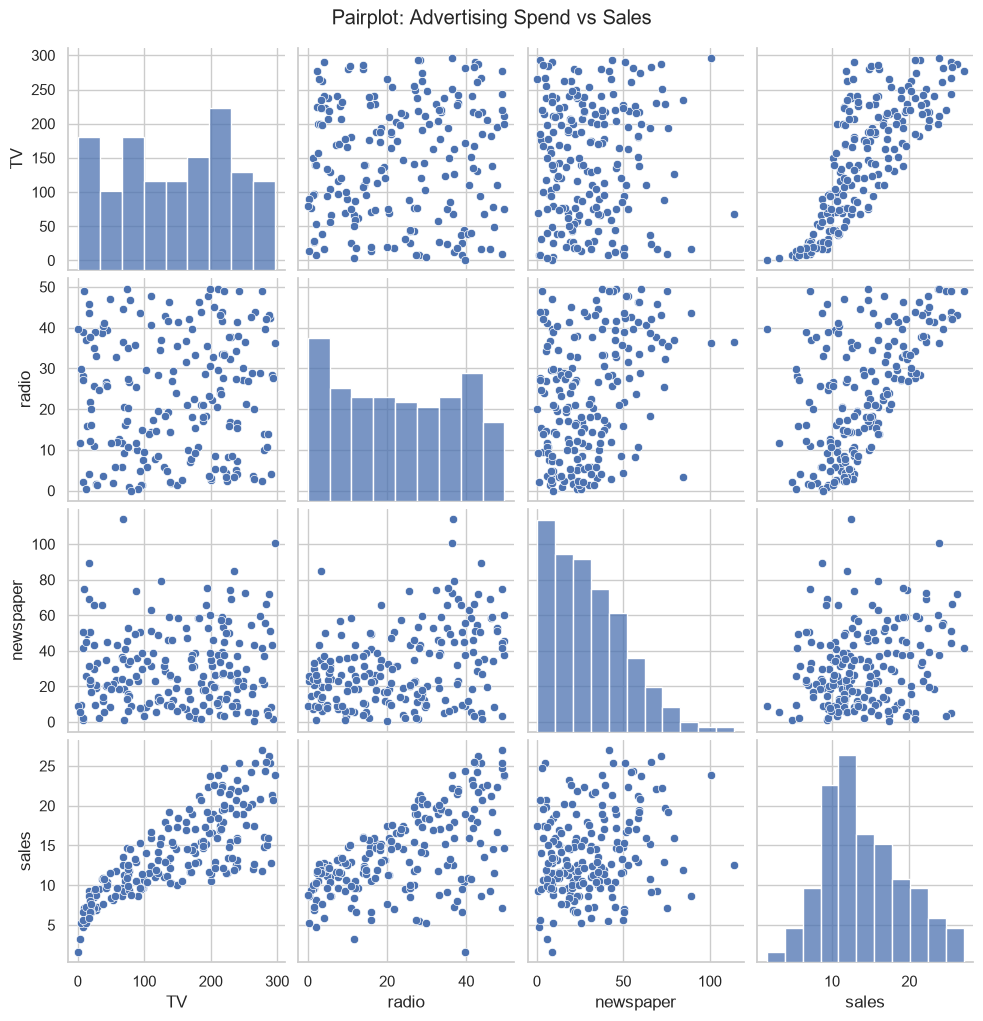

In [8]:
# Pairplot to visualize relationships between all features
sns.pairplot(df, diag_kind="hist")
plt.suptitle("Pairplot: Advertising Spend vs Sales", y=1.02)
plt.show()

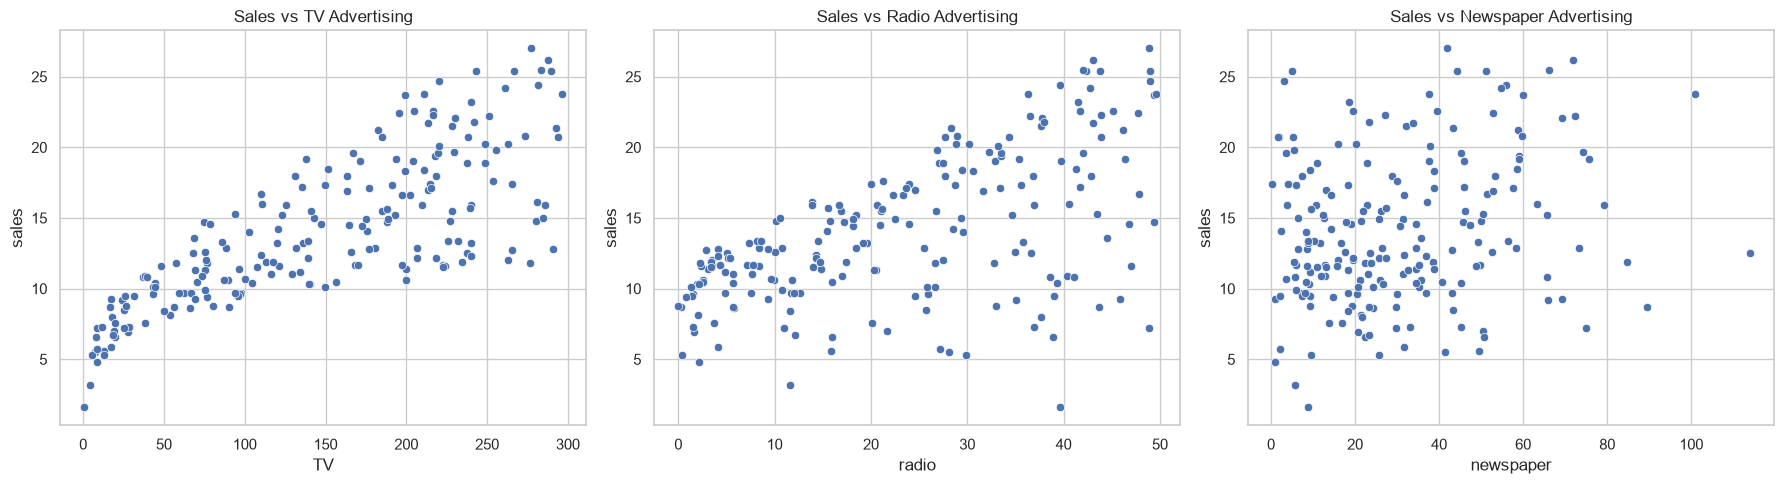

In [13]:
# Create scatter plots for each advertising channel
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# TV vs Sales
sns.scatterplot(data=df, x="TV", y="sales", ax=axes[0])
axes[0].set_title("Sales vs TV Advertising")

# Radio vs Sales
sns.scatterplot(data=df, x="radio", y="sales", ax=axes[1])
axes[1].set_title("Sales vs Radio Advertising")

# Newspaper vs Sales
sns.scatterplot(data=df, x="newspaper", y="sales", ax=axes[2])
axes[2].set_title("Sales vs Newspaper Advertising")

plt.tight_layout()
plt.show()

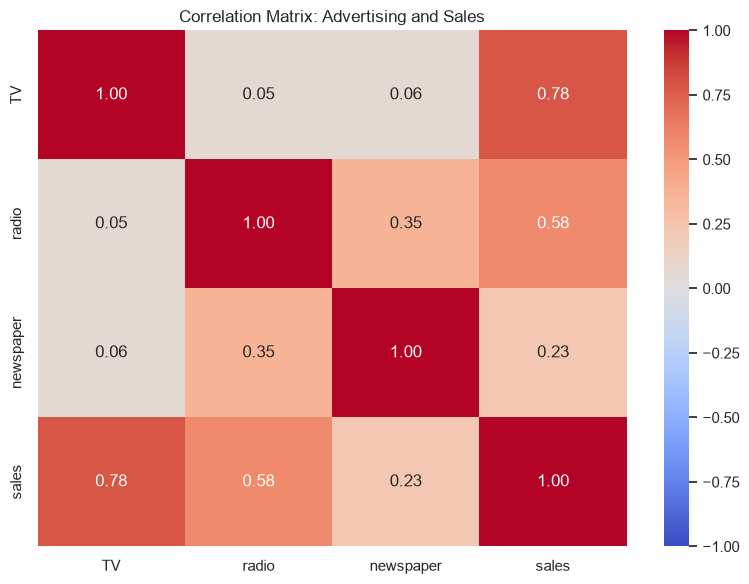

In [14]:
# Correlation between advertising channels and sales
correlation_matrix = df[["TV", "radio", "newspaper", "sales"]].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix: Advertising and Sales")
plt.tight_layout()
plt.show()

In [15]:
# Select input features and target
X = df[["TV", "radio", "newspaper"]]
y = df["sales"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (160, 3)
Testing data: (40, 3)
Training target: (160,)
Testing target: (40,)


In [16]:
# Create and train the baseline model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict sales for test data
lr_predictions = lr_model.predict(X_test)

print("Linear Regression model trained successfully!")
print("Intercept:", round(lr_model.intercept_, 4))

# Display feature coefficients
coefficients = pd.DataFrame({
    "Advertising Channel": X.columns,
    "Coefficient": lr_model.coef_
})

display(coefficients)

Linear Regression model trained successfully!
Intercept: 2.9791


,Advertising Channel,Coefficient
0,TV,0.044730
1,radio,0.189195
2,newspaper,0.002761


In [17]:
# Train the second model: Random Forest Regressor
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

# Predict sales
rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [18]:
# Function to evaluate regression models
def evaluate_model_regression(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }

# Compare both models
results = [
    evaluate_model_regression(
        y_test, lr_predictions, "Linear Regression"
    ),
    evaluate_model_regression(
        y_test, rf_predictions, "Random Forest"
    )
]

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.4608,1.7816,0.8994
1,Random Forest,0.6289,0.7577,0.9818


In [19]:
# Select the model with the lower RMSE
best_model_name = results_df.loc[
    results_df["RMSE"].idxmin(), "Model"
]

if best_model_name == "Linear Regression":
    best_model = lr_model
    best_predictions = lr_predictions
else:
    best_model = rf_model
    best_predictions = rf_predictions

print("Best model based on RMSE:", best_model_name)

Best model based on RMSE: Random Forest


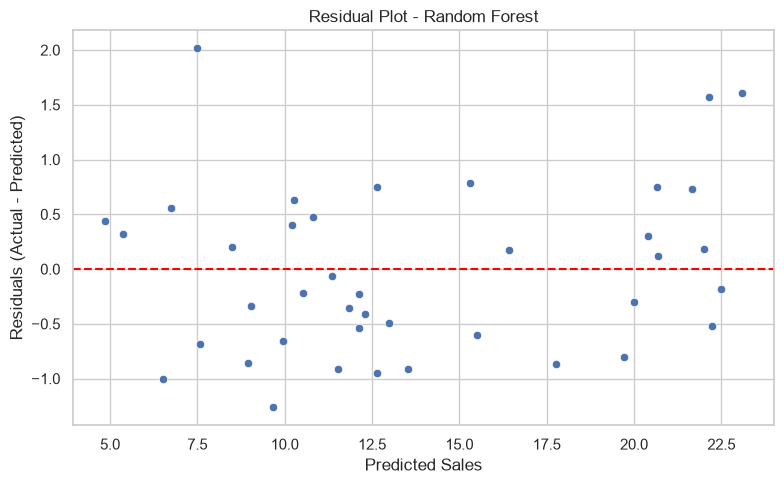

In [20]:
# Calculate residuals: actual sales minus predicted sales
residuals = y_test - best_predictions

plt.figure(figsize=(8, 5))
sns.scatterplot(x=best_predictions, y=residuals)

# Zero-error reference line
plt.axhline(y=0, color="red", linestyle="--")

plt.title(f"Residual Plot - {best_model_name}")
plt.xlabel("Predicted Sales")
plt.ylabel("Residuals (Actual - Predicted)")
plt.tight_layout()
plt.show()

Linear Regression Coefficients:


,Channel,Coefficient
1,radio,0.1892
0,TV,0.0447
2,newspaper,0.0028


Random Forest Feature Importance:


,Channel,Importance
0,TV,0.6247
1,radio,0.3621
2,newspaper,0.0131


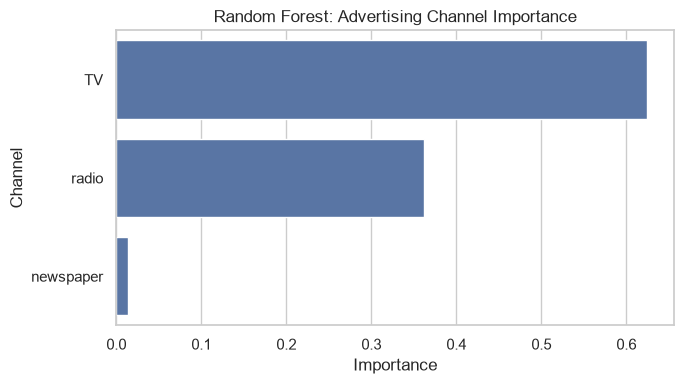

In [21]:
# Linear Regression coefficients
lr_importance = pd.DataFrame({
    "Channel": X.columns,
    "Coefficient": lr_model.coef_
})

print("Linear Regression Coefficients:")
display(lr_importance.sort_values(
    by="Coefficient", key=abs, ascending=False
).round(4))

# Random Forest feature importance
rf_importance = pd.DataFrame({
    "Channel": X.columns,
    "Importance": rf_model.feature_importances_
})

print("Random Forest Feature Importance:")
display(rf_importance.sort_values(
    by="Importance", ascending=False
).round(4))

# Plot feature importance
plt.figure(figsize=(7, 4))
sns.barplot(
    data=rf_importance.sort_values(
        by="Importance", ascending=False
    ),
    x="Importance",
    y="Channel"
)
plt.title("Random Forest: Advertising Channel Importance")
plt.tight_layout()
plt.show()